# Tutorial 2 — weMERFISH scenarios, quantitative metrics and niche heterogeneity

This notebook analyses five real NTF runs on the 6-somite weMERFISH zebrafish
embryo (25,858 cells, 495 genes). It covers interpolation, gap filling and
boundary extrapolation, then evaluates both expression reconstruction and
biological structure.

![NTF can conduct extrapolative prediction beyond observed boundaries](../figures/extrapolate.jpg)

*NTF can conduct spatial interpolative prediction between observed sections and extrapolative prediction beyond observed boundaries.*

The zebrafish weMERFISH data used here can be downloaded from [Zenodo](https://doi.org/10.5281/zenodo.19590993).

In [1]:
from pathlib import Path
import os
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, fowlkes_mallows_score, normalized_mutual_info_score

candidates = ([Path(os.environ["NTF_ROOT"])] if os.getenv("NTF_ROOT") else []) + [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "NTF" / "train.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set NTF_ROOT to the cloned NTF repository root.")
sys.path.insert(0, str(ROOT))

INPUT_PATH = Path(os.getenv(
    "NTF_WEMERFISH_DATA",
    ROOT / "mytrain/data/wemerfish_zebrafish_embryo/processed/wemerfish_C6s_E2.h5ad", # The zebrafish weMERFISH data used here can be downloaded from https://doi.org/10.5281/zenodo.19590993.
))
OUTPUT_DIR = Path(os.getenv("NTF_TUTORIAL_OUTPUT", ROOT / "tutorial/outputs/02_wemerfish"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAINING_ITERATIONS = int(os.getenv("NTF_TRAINING_ITERATIONS", "20000"))
TRAINING_DEVICE = os.getenv("NTF_DEVICE", "cuda:0")
default_results = OUTPUT_DIR / "reproduction/models"
RESULTS_DIR = Path(os.getenv("NTF_WEMERFISH_RESULTS", default_results))

SCENARIOS = {
    "senario1": {"label": "Scenario 1", "split": "group", "description": "interleaved held-out sections"},
    "senario2": {"label": "Scenario 2", "split": "group2", "description": "contiguous middle gap"},
    "senario3": {"label": "Scenario 3", "split": "group4", "description": "both-end extrapolation"},
    "head": {"label": "Head", "split": "head", "description": "head-end extrapolation"},
    "tail": {"label": "Tail", "split": "tail", "description": "tail-end extrapolation"},
}
if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"Required input not found: {INPUT_PATH}\nSee tutorial/README.md for data preparation.")

sns.set_theme(style="white", context="notebook")
print(f"Input: {os.path.relpath(INPUT_PATH, ROOT)}")
print(f"NTF results: {os.path.relpath(RESULTS_DIR, ROOT)}")
print(f"Output: {os.path.relpath(OUTPUT_DIR, ROOT)}")

Input: mytrain/data/wemerfish_zebrafish_embryo/processed/wemerfish_C6s_E2.h5ad
NTF results: ../../../../../../home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain/reproduction/models
Output: ../../../../../../home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain
Full notebook training: True


## 1. Complete model training in this notebook

The following cell trains five independent NTF models
from the processed input, then performs test-coordinate inference, cell type annotation and the official evaluation for each scenario. The commands run
sequentially on `NTF_DEVICE` (default `cuda:0`). Each run uses 20,000 iterations by
default; `NTF_TRAINING_ITERATIONS` can override this for a separate smoke test.

In [2]:

import subprocess
import time

training_log_dir = RESULTS_DIR.parent / "logs"
training_log_dir.mkdir(parents=True, exist_ok=True)
training_rows = []
for scenario, info in SCENARIOS.items():
    scenario_dir = RESULTS_DIR / scenario
    for filename in ["best_model.pth", "test_results.h5ad"]:
        existing = scenario_dir / filename
        if existing.exists():
            raise FileExistsError(f"Training requires fresh outputs; found {existing}. Choose a new NTF_TUTORIAL_OUTPUT.")

    command = [
        sys.executable, str(ROOT / "scripts/train_and_eval.py"),
        "--input_data", str(INPUT_PATH),
        "--output_dir", str(scenario_dir),
        "--log_dir", str(scenario_dir / "runs"),
        "--slice_id", "slice_id",
        "--split_mode", "label",
        "--split_column", info["split"],
        "--train_label", "train",
        "--test_label", "test",
        "--cat_keys", "clusters", "type",
        "--device", TRAINING_DEVICE,
        "--n_iter", str(TRAINING_ITERATIONS),
        "--batch_size", "8192",
    ]
    log_path = training_log_dir / f"{scenario}.log"
    print(f"\n[{info['label']}] {' '.join(command)}", flush=True)
    started = time.monotonic()
    environment = os.environ.copy()
    environment["PYTHONUNBUFFERED"] = "1"
    process = subprocess.Popen(
        command, cwd=ROOT, env=environment,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1,
    )
    transcript = []
    markers = ["Data split", "KNN label annotator built", "Iter:", "Early stopping",
                "Training finished", "Inference finished", "Test results saved"]
    with log_path.open("w") as log:
        for line in process.stdout:
            log.write(line)
            transcript.append(line)
            if any(marker in line for marker in markers):
                print(line.rstrip(), flush=True)
    return_code = process.wait()
    if return_code != 0:
        print("".join(transcript[-50:]))
        raise subprocess.CalledProcessError(return_code, command)
    for filename in ["best_model.pth", "label_annotator.pkl", "test_results.h5ad", "gene_metrics.csv"]:
        path = scenario_dir / filename
        if not path.is_file() or path.stat().st_size == 0:
            raise FileNotFoundError(f"Training did not produce {path}")
    elapsed_minutes = (time.monotonic() - started) / 60
    training_rows.append({
        "scenario": scenario,
        "split_column": info["split"],
        "iterations": TRAINING_ITERATIONS,
        "elapsed_minutes": elapsed_minutes,
        "log": os.path.relpath(log_path, ROOT),
    })
    print(f"[{info['label']}] completed in {elapsed_minutes:.2f} min; outputs passed freshness checks.", flush=True)

training_runs = pd.DataFrame(training_rows)
training_runs.to_csv(OUTPUT_DIR / "training_runs.csv", index=False)
display(training_runs.round({"elapsed_minutes": 2}))


[Scenario 1] /home/gongyuqiao/.conda/envs/ntf/bin/python /mnt/experiments/gongyq/analysis_link/ur_annotation/NTF/scripts/train_and_eval.py --input_data /mnt/experiments/gongyq/analysis_link/ur_annotation/NTF/mytrain/data/wemerfish_zebrafish_embryo/processed/wemerfish_C6s_E2.h5ad --output_dir /home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain/reproduction/models/senario1 --log_dir /home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain/reproduction/models/senario1/runs --slice_id slice_id --split_mode label --split_column group --train_label train --test_label test --cat_keys clusters type --device cuda:0 --n_iter 20000 --batch_size 8192


2026-11-18 18:35:55,770 - INFO - Data split into training set (14546 cells) and test set (11312 cells).


2026-11-18 18:35:57,574 - INFO - KNN label annotator built on 14546 reference points (k=5) for: ['clusters', 'type']


Iter: 600, Loss: 1843.588064, Best: 1843.588064, Patience: 0/5


Iter: 800, Loss: 1830.947146, Best: 1830.947146, Patience: 0/5


Iter: 1000, Loss: 1810.272820, Best: 1810.272820, Patience: 0/5


... (516 outputs left out)

2026-11-18 19:26:12,939 - INFO - Inference finished. Time elapsed: 0.20 seconds


2026-11-18 19:26:17,002 - INFO - Test results saved to /home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain/reproduction/models/tail/test_results.h5ad


[Tail] completed in 14.56 min; outputs passed freshness checks.


,scenario,split_column,iterations,elapsed_minutes,log
0,senario1,group,20000,8.68,../../../../../../home/gongyuqiao/ur_annotatio...
1,senario2,group2,20000,7.76,../../../../../../home/gongyuqiao/ur_annotatio...
2,senario3,group4,20000,7.46,../../../../../../home/gongyuqiao/ur_annotatio...
3,head,head,20000,11.98,../../../../../../home/gongyuqiao/ur_annotatio...
4,tail,tail,20000,14.56,../../../../../../home/gongyuqiao/ur_annotatio...


## 2. Scenario design and alignment checks

The 16 virtual z-sections are quantile-binned to similar cell counts. The
annotation hierarchy is `germlayer` → `type` (10 niches) → `tissue` →
`clusters` (51 fine cell types). Every prediction is checked against the
corresponding test split for cell order, coordinates and ground-truth labels.


,scenario,split_column,task,test_sections,n_test_cells
0,Scenario 1,group,interleaved held-out sections,"2, 4, 6, 8, 10, 12, 14",11312
1,Scenario 2,group2,contiguous middle gap,"8, 9, 10",4848
2,Scenario 3,group4,both-end extrapolation,"1, 2, 15, 16",6466
3,Head,head,head-end extrapolation,"1, 2",3233
4,Tail,tail,tail-end extrapolation,"15, 16",3233


/tmp/ipykernel_1508601/2046351663.py:27: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(split_long.replace({"Train": 0, "Test": 1}).astype(int), cmap=sns.color_palette(["#D9D9D9", "#82659C"]), cbar=False, linewidths=0.4, linecolor="white", ax=ax)


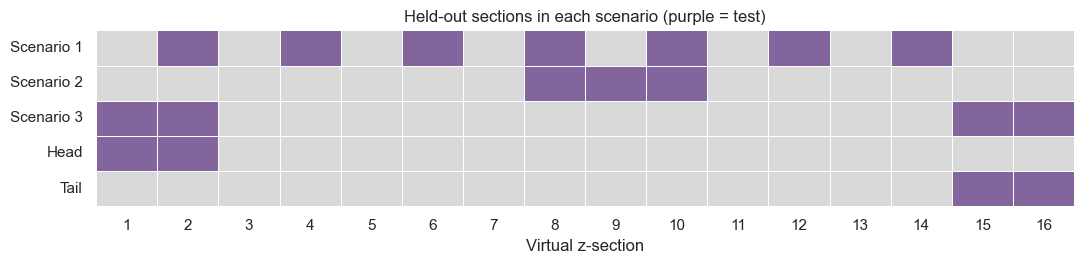

In [3]:
input_data = ad.read_h5ad(INPUT_PATH)
results = {scenario: ad.read_h5ad(RESULTS_DIR / scenario / "test_results.h5ad") for scenario in SCENARIOS}
scenario_rows = []
for scenario, info in SCENARIOS.items():
    result = results[scenario]
    expected = input_data[input_data.obs[info["split"]].astype(str) == "test"]
    assert result.obs_names.equals(expected.obs_names), f"Cell order mismatch: {scenario}"
    assert np.allclose(result.obsm["spatial"], expected.obsm["spatial"]), f"Coordinate mismatch: {scenario}"
    for key in ["type", "clusters", "tissue"]:
        assert result.obs[key].astype(str).equals(expected.obs[key].astype(str)), f"Label mismatch: {scenario}/{key}"
    test_slices = sorted(result.obs["slice_id"].unique().astype(int))
    scenario_rows.append({
        "scenario": info["label"], "split_column": info["split"], "task": info["description"],
        "test_sections": ", ".join(map(str, test_slices)), "n_test_cells": result.n_obs,
    })
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)

split_matrix = []
for scenario, info in SCENARIOS.items():
    split_matrix.append([
        "Test" if input_data.obs.loc[input_data.obs["slice_id"] == sid, info["split"]].astype(str).eq("test").all() else "Train"
        for sid in range(1, 17)
    ])
split_long = pd.DataFrame(split_matrix, index=[v["label"] for v in SCENARIOS.values()], columns=range(1, 17))
fig, ax = plt.subplots(figsize=(11, 2.8))
sns.heatmap(split_long.replace({"Train": 0, "Test": 1}).astype(int), cmap=sns.color_palette(["#D9D9D9", "#82659C"]), cbar=False, linewidths=0.4, linecolor="white", ax=ax)
ax.set_xlabel("Virtual z-section")
ax.set_ylabel("")
ax.set_title("Held-out sections in each scenario (purple = test)")
fig.tight_layout()
display(fig)
plt.close(fig)


## 3. Reconstruction metrics

Pearson, Spearman and RMSE are recomputed from `X` and `layers['prediction']`
for every gene. The 3D SSIM column is read from the official NTF output, where
it was calculated with the same spatial-grid implementation as the benchmark.
Correlations summarize pattern agreement, RMSE summarizes scale error and
SSIM summarizes local 3D structural similarity.


In [4]:
def dense(matrix):
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

def expression_metrics(result, scenario):
    from scipy.stats import pearsonr, spearmanr

    truth = dense(result.X).astype(np.float64)
    prediction = dense(result.layers["prediction"]).astype(np.float64)
    assert truth.shape == prediction.shape and np.isfinite(prediction).all()
    pearson, spearman = [], []
    for j in range(result.n_vars):
        observed = truth[:, j]
        predicted = prediction[:, j]
        nonzero = observed > 0
        if nonzero.sum() < 2 or np.var(observed[nonzero]) < 1e-10 or np.var(predicted[nonzero]) < 1e-10:
            pearson.append(np.nan)
            spearman.append(np.nan)
        else:
            pearson.append(pearsonr(observed, predicted).statistic)
            spearman.append(spearmanr(observed, predicted).statistic)
    return pd.DataFrame({
        "scenario": scenario,
        "gene": result.var_names,
        "pearson": pearson,
        "spearman": spearman,
        "rmse": np.sqrt(((truth - prediction) ** 2).mean(axis=0)),
        "ssim_3d": result.var["ssim_3d"].to_numpy(),
    })

gene_metrics = pd.concat([expression_metrics(results[s], s) for s in SCENARIOS], ignore_index=True)
gene_metrics["scenario_label"] = gene_metrics["scenario"].map({s: v["label"] for s, v in SCENARIOS.items()})
reconstruction_summary = gene_metrics.groupby(["scenario", "scenario_label"], sort=False)[["pearson", "spearman", "rmse", "ssim_3d"]].mean().reset_index()
gene_metrics.to_csv(OUTPUT_DIR / "reconstruction_gene_metrics.csv", index=False)
reconstruction_summary.to_csv(OUTPUT_DIR / "reconstruction_summary.csv", index=False)
display(reconstruction_summary.round(4))


,scenario,scenario_label,pearson,spearman,rmse,ssim_3d
0,senario1,Scenario 1,0.2788,0.2366,1.0994,0.6362
1,senario2,Scenario 2,0.2436,0.2040,1.1026,0.6783
2,senario3,Scenario 3,0.1468,0.1084,1.1725,0.6095
3,head,Head,0.1843,0.1521,1.1432,0.6335
4,tail,Tail,0.1132,0.0877,1.1504,0.8116


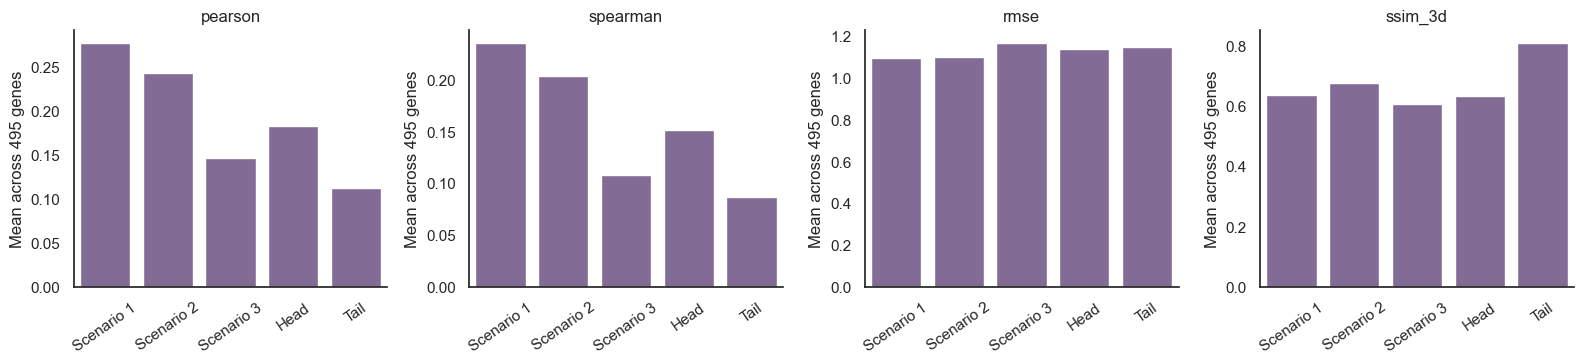

In [5]:
plot_metrics = reconstruction_summary.melt(id_vars=["scenario", "scenario_label"], value_vars=["pearson", "spearman", "rmse", "ssim_3d"], var_name="metric", value_name="value")
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, metric in zip(axes, ["pearson", "spearman", "rmse", "ssim_3d"]):
    subset = plot_metrics[plot_metrics["metric"] == metric]
    sns.barplot(data=subset, x="scenario_label", y="value", color="#82659C", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Mean across 495 genes")
    ax.tick_params(axis="x", rotation=35)
    sns.despine(ax=ax)
fig.tight_layout()
display(fig)
plt.close(fig)


## 4. Cell-type and niche label agreement

NTF's cell type annotator transfers both fine cell types (`clusters`)
and broader niches (`type`). ARI, NMI and FMI compare predicted and observed
labels on exactly the same test cells. 


In [6]:
def label_metrics(truth, prediction):
    return {
        "ARI": adjusted_rand_score(truth, prediction),
        "NMI": normalized_mutual_info_score(truth, prediction),
        "FMI": fowlkes_mallows_score(truth, prediction),
    }

label_rows = []
for scenario, result in results.items():
    for level, prediction_key in [("cell type (clusters)", "pred_clusters"), ("niche (type)", "pred_type")]:
        row = {"scenario": scenario, "scenario_label": SCENARIOS[scenario]["label"], "level": level}
        row.update(label_metrics(result.obs[level.split("(")[1][:-1]].astype(str), result.obs[prediction_key].astype(str)))
        label_rows.append(row)
label_summary = pd.DataFrame(label_rows)
label_summary.to_csv(OUTPUT_DIR / "label_metrics.csv", index=False)
display(label_summary.round(4))


,scenario,scenario_label,level,ARI,NMI,FMI
0,senario1,Scenario 1,cell type (clusters),0.5244,0.6823,0.5416
1,senario1,Scenario 1,niche (type),0.6803,0.5817,0.7463
2,senario2,Scenario 2,cell type (clusters),0.5477,0.7017,0.5660
3,senario2,Scenario 2,niche (type),0.6670,0.5972,0.7348
4,senario3,Scenario 3,cell type (clusters),0.3047,0.5994,0.3405
5,senario3,Scenario 3,niche (type),0.3858,0.3868,0.5734
6,head,Head,cell type (clusters),0.2046,0.5047,0.2986
7,head,Head,niche (type),0.2114,0.2240,0.4610
8,tail,Tail,cell type (clusters),0.4268,0.6385,0.4657
9,tail,Tail,niche (type),0.5243,0.5426,0.7061


### Complete cell-type spatial maps

Every held-out section is shown without subsampling. The top row contains the
observed `clusters` labels and the bottom row contains NTF's `pred_clusters`.
Each NTF panel is annotated with the ARI calculated within that section; the
figure title reports the overall ARI across all test cells in the scenario.
Colors are fixed across sections and scenarios. Figures are exported as both
PNG and SVG, together with the per-section ARI table.


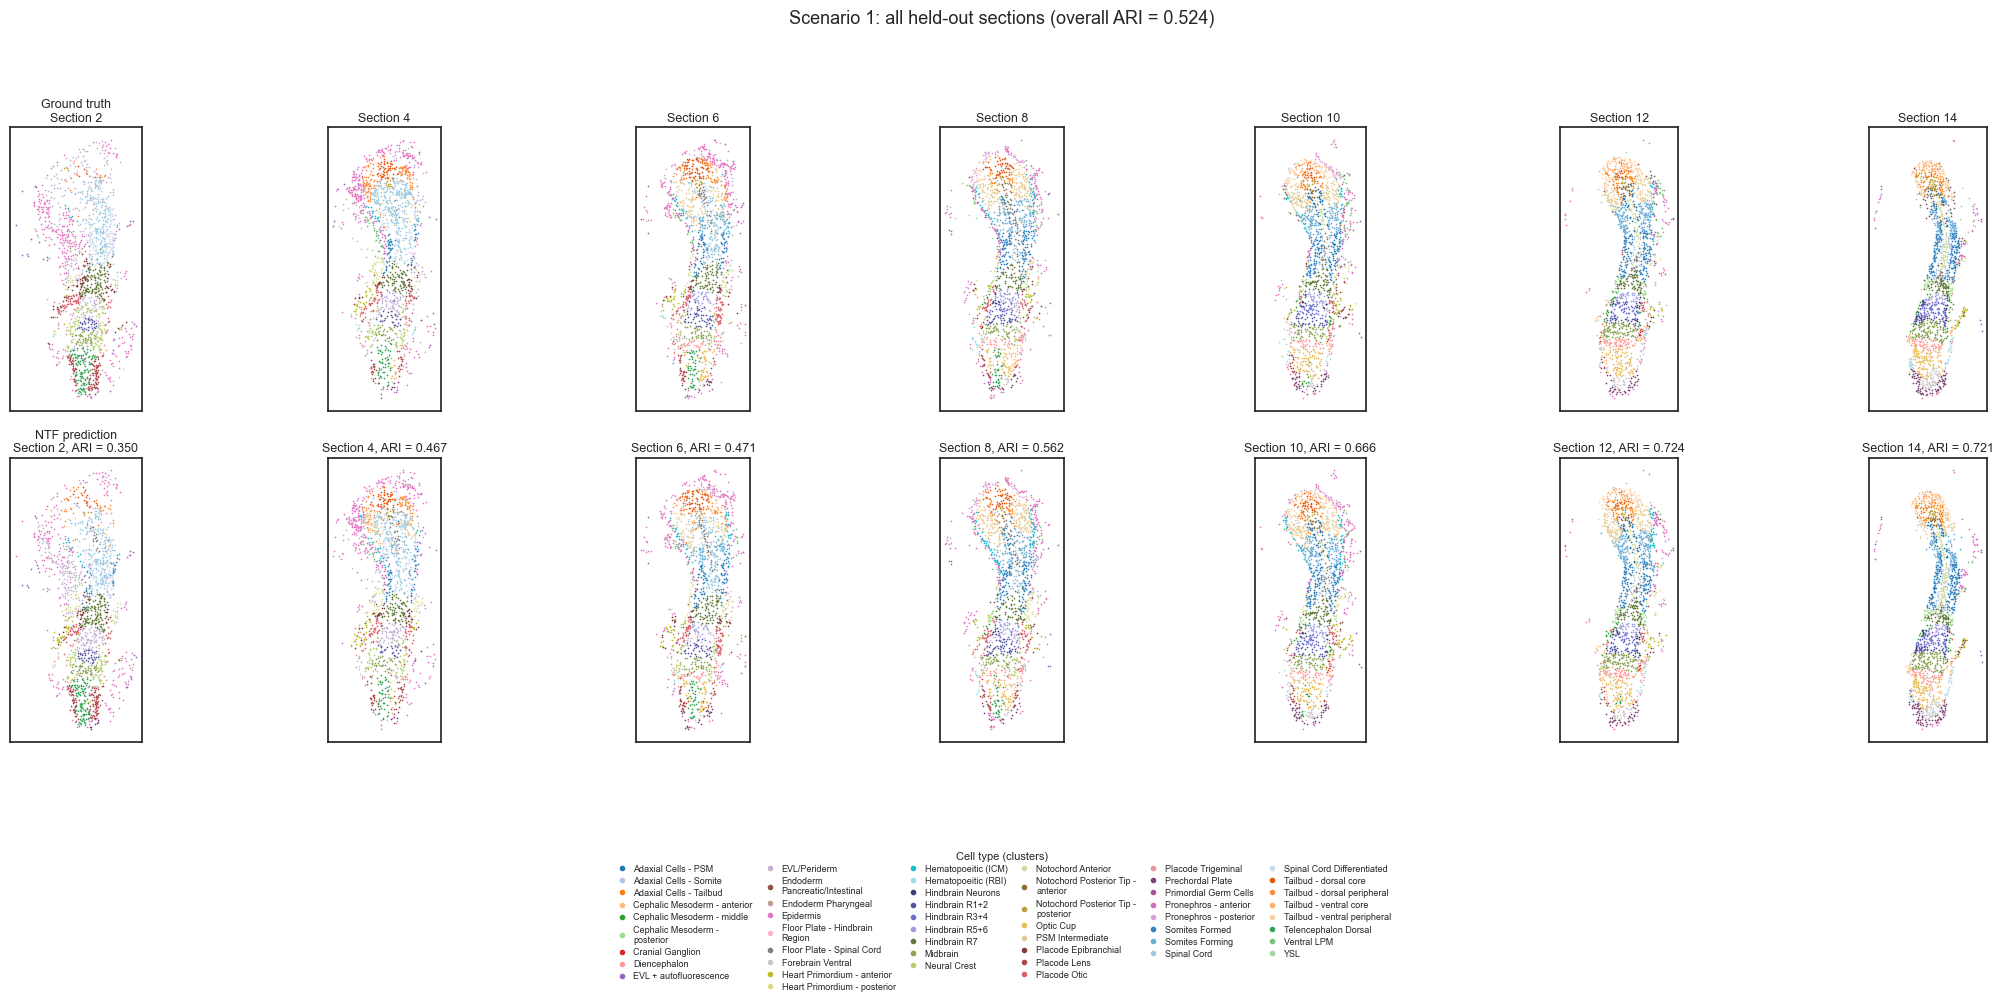

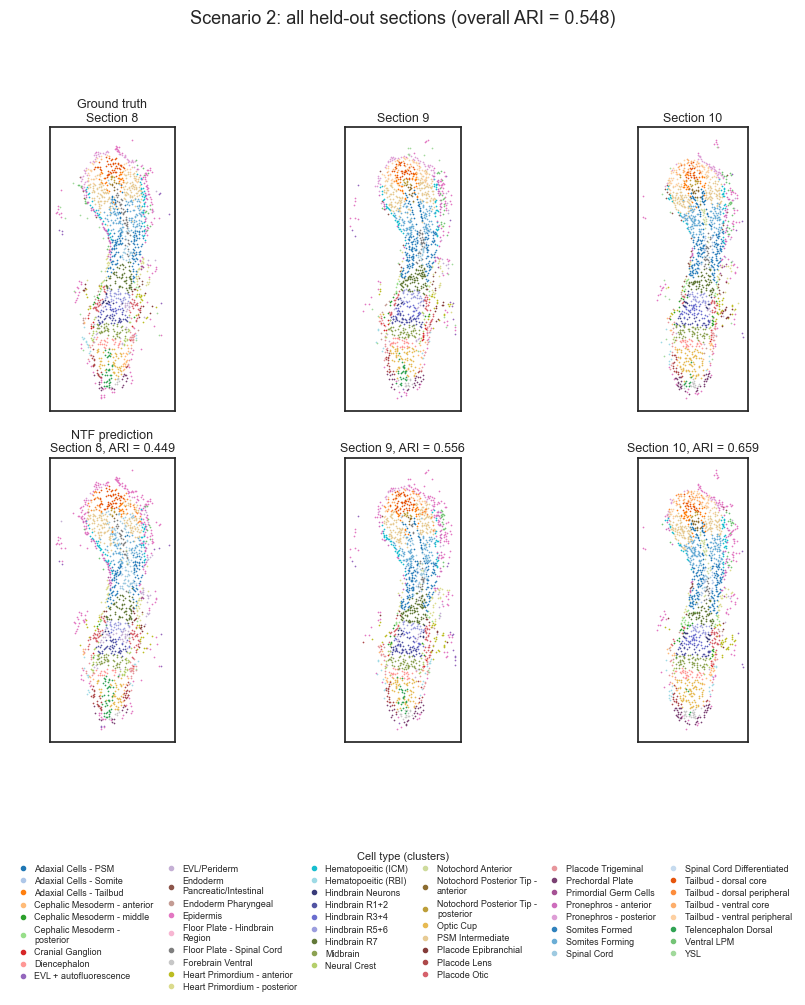

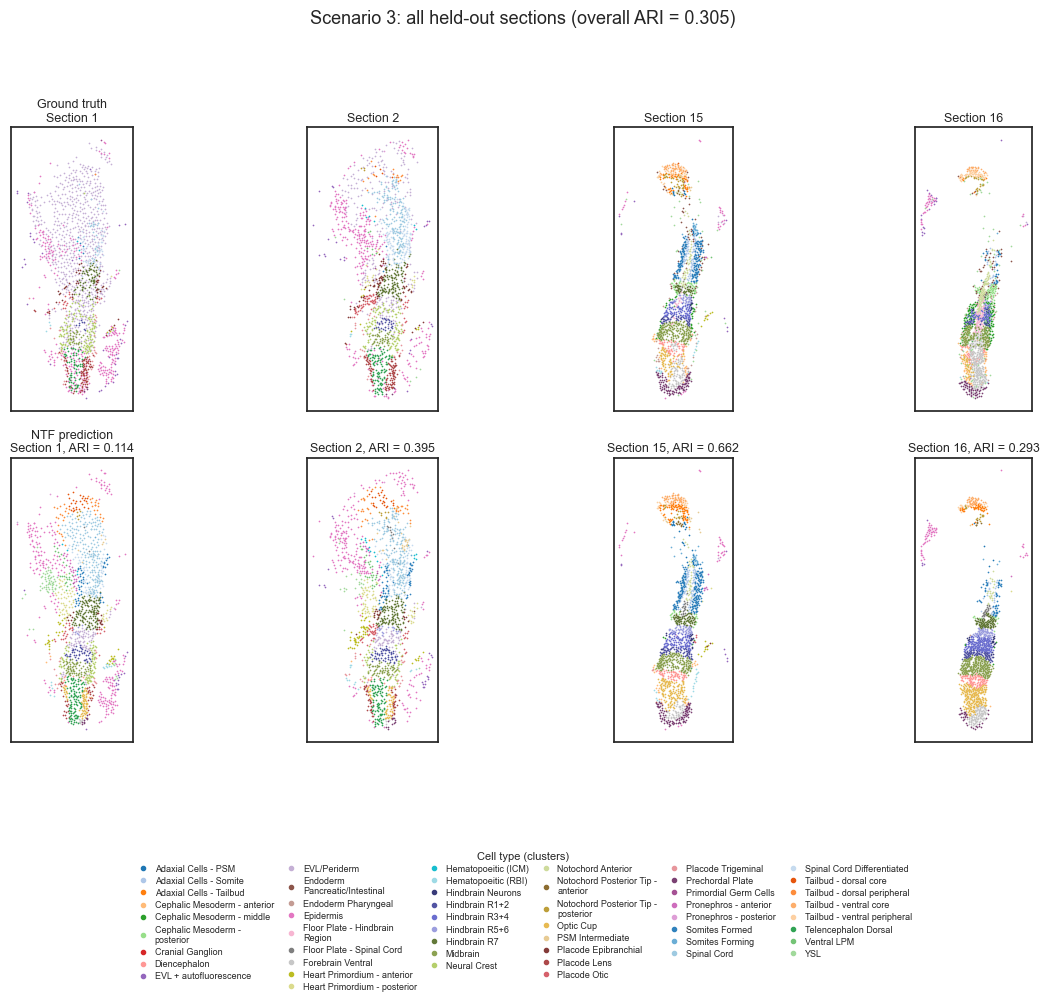

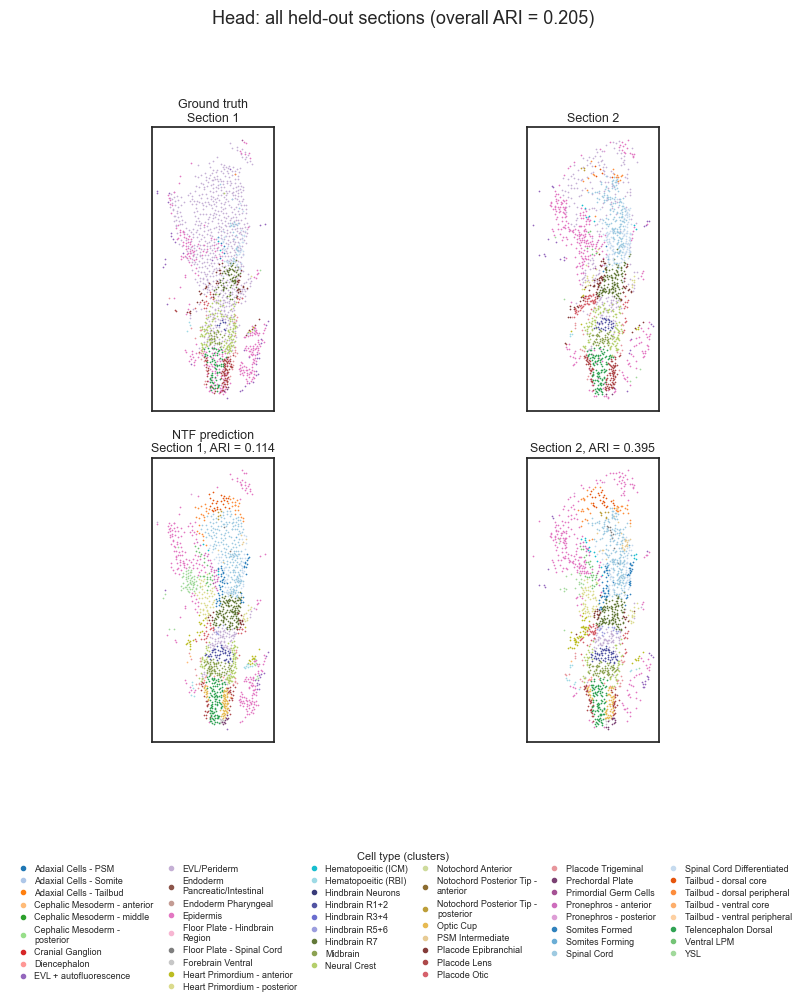

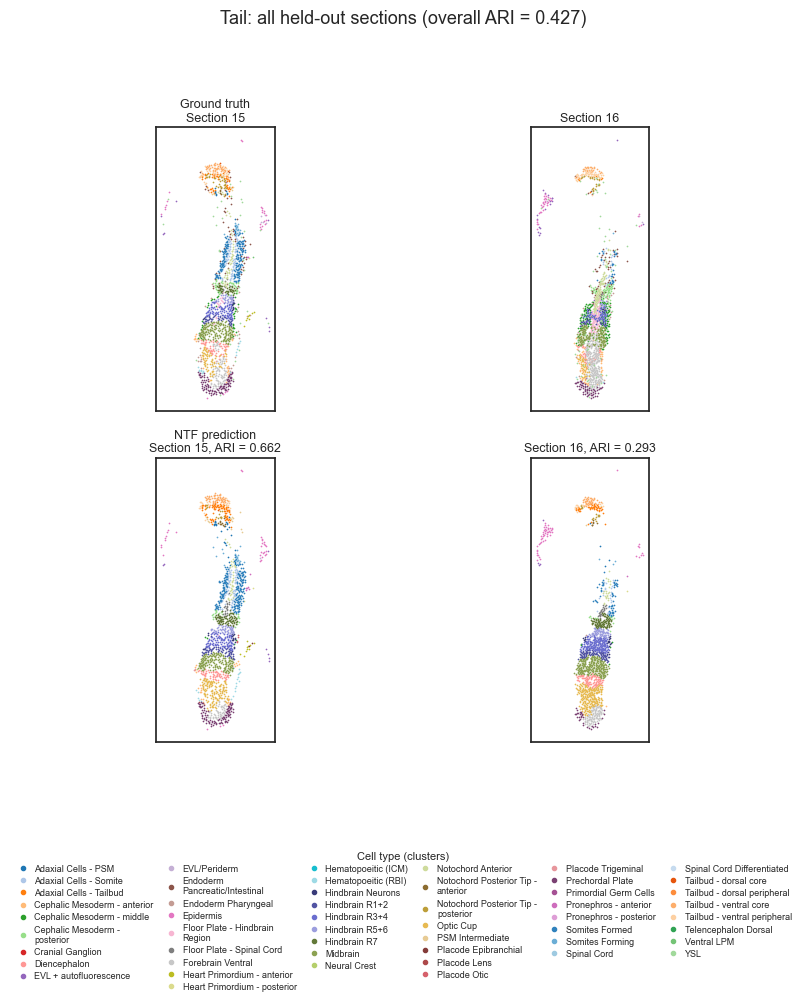

Saved 5 complete spatial-map figure sets to /home/gongyuqiao/ur_annotation/NTF/mytrain/revision/experiment/code_tutorial_notebooks/outputs/02_wemerfish_notebook_full_retrain/celltype_spatial


,scenario,scenario_label,slice_id,n_cells,ARI
0,senario1,Scenario 1,2,1616,0.3499
1,senario1,Scenario 1,4,1616,0.4669
2,senario1,Scenario 1,6,1616,0.4707
3,senario1,Scenario 1,8,1616,0.5620
4,senario1,Scenario 1,10,1616,0.6660
5,senario1,Scenario 1,12,1616,0.7244
6,senario1,Scenario 1,14,1616,0.7214
7,senario2,Scenario 2,8,1616,0.4489
8,senario2,Scenario 2,9,1616,0.5555
9,senario2,Scenario 2,10,1616,0.6591


In [7]:
import textwrap

celltype_fig_dir = OUTPUT_DIR / "celltype_spatial"
celltype_fig_dir.mkdir(parents=True, exist_ok=True)

gt_categories = sorted(input_data.obs["clusters"].astype(str).unique())
pred_categories = set().union(*(set(result.obs["pred_clusters"].astype(str)) for result in results.values()))
palette_categories = gt_categories + sorted(pred_categories.difference(gt_categories))
palette_colors = (list(plt.get_cmap("tab20").colors)
                  + list(plt.get_cmap("tab20b").colors)
                  + list(plt.get_cmap("tab20c").colors))
celltype_palette = {category: palette_colors[i % len(palette_colors)] for i, category in enumerate(palette_categories)}

def plot_celltype_panel(ax, coords, labels, title):
    for category in palette_categories:
        selected = labels == category
        if selected.any():
            ax.scatter(coords[selected, 0], coords[selected, 1], s=1.5,
                       color=celltype_palette[category], linewidths=0, rasterized=True)
    ax.set_title(title, fontsize=9, pad=4)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])

def add_celltype_legend(fig, figure_height):
    handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=3,
                          color=celltype_palette[category]) for category in gt_categories]
    labels = [textwrap.fill(category, 28) for category in gt_categories]
    n_columns = 6
    n_rows = int(np.ceil(len(labels) / n_columns))
    legend_height = 0.35 + n_rows * 0.22
    bottom = min((legend_height + 0.12) / figure_height, 0.35)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.005),
               ncol=n_columns, fontsize=6.5, frameon=False, title="Cell type (clusters)",
               title_fontsize=8, columnspacing=0.9, handletextpad=0.3, labelspacing=0.35)
    return bottom

spatial_metric_rows = []
for scenario, result in results.items():
    coords = np.asarray(result.obsm["spatial"])
    sections = result.obs["slice_id"].astype(int).to_numpy()
    section_ids = sorted(np.unique(sections))
    truth = result.obs["clusters"].astype(str).to_numpy()
    prediction = result.obs["pred_clusters"].astype(str).to_numpy()
    overall_ari = adjusted_rand_score(truth, prediction)

    figure_height = 10.0
    figure_width = max(3.2 * len(section_ids), 9.6)
    fig, axes = plt.subplots(2, len(section_ids), figsize=(figure_width, figure_height), squeeze=False)
    for row, labels in enumerate([truth, prediction]):
        for column, section_id in enumerate(section_ids):
            selected = sections == section_id
            if row == 0:
                title = f"Ground truth\nSection {section_id}" if column == 0 else f"Section {section_id}"
            else:
                section_ari = adjusted_rand_score(truth[selected], prediction[selected])
                spatial_metric_rows.append({
                    "scenario": scenario,
                    "scenario_label": SCENARIOS[scenario]["label"],
                    "slice_id": section_id,
                    "n_cells": int(selected.sum()),
                    "ARI": section_ari,
                })
                title = (f"NTF prediction\nSection {section_id}, ARI = {section_ari:.3f}" if column == 0
                         else f"Section {section_id}, ARI = {section_ari:.3f}")
            plot_celltype_panel(axes[row, column], coords[selected], labels[selected], title)

    bottom = add_celltype_legend(fig, figure_height)
    fig.suptitle(f"{SCENARIOS[scenario]['label']}: all held-out sections (overall ARI = {overall_ari:.3f})",
                 fontsize=13, y=0.995)
    fig.tight_layout(rect=[0, bottom, 1, 0.96])
    fig.savefig(celltype_fig_dir / f"celltype_spatial_{scenario}.png", dpi=180, facecolor="white")
    fig.savefig(celltype_fig_dir / f"celltype_spatial_{scenario}.svg", facecolor="white")
    display(fig)
    plt.close(fig)

celltype_per_section = pd.DataFrame(spatial_metric_rows)
celltype_per_section.to_csv(OUTPUT_DIR / "celltype_per_section_metrics.csv", index=False)
print(f"Saved {len(results)} complete spatial-map figure sets to {celltype_fig_dir}")
display(celltype_per_section.round({"ARI": 4}))


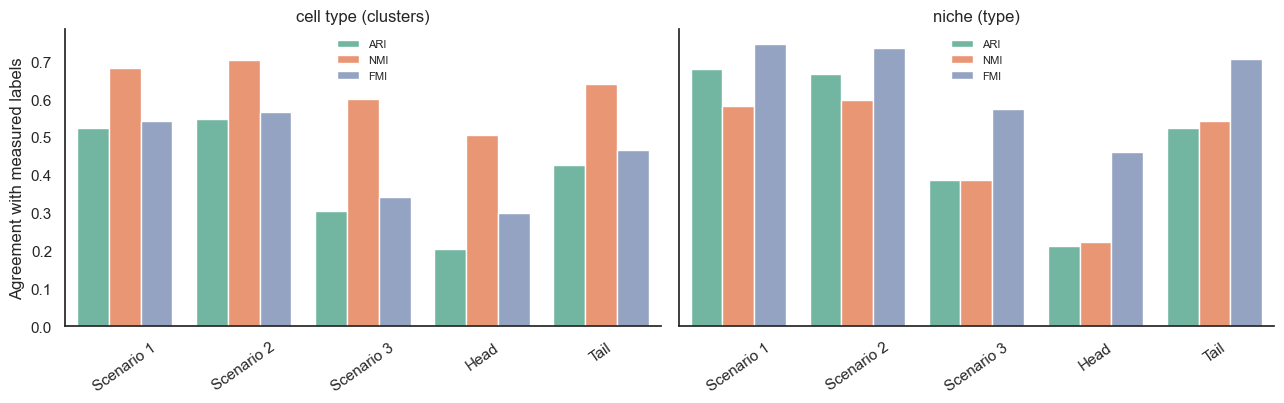

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, level in zip(axes, ["cell type (clusters)", "niche (type)"]):
    subset = label_summary[label_summary["level"] == level].melt(id_vars=["scenario_label"], value_vars=["ARI", "NMI", "FMI"], var_name="metric", value_name="value")
    sns.barplot(data=subset, x="scenario_label", y="value", hue="metric", palette="Set2", ax=ax)
    ax.set_title(level)
    ax.set_xlabel("")
    ax.set_ylabel("Agreement with measured labels")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(frameon=False, fontsize=8)
    sns.despine(ax=ax)
fig.tight_layout()
display(fig)
plt.close(fig)


## 5. Niche heterogeneity: composition and frequency

A niche is not treated as a homogeneous label. For each observed niche, we
compute its fraction of the 51 measured `clusters` and compare that vector
with the composition inside the corresponding predicted niche. As in the
official evaluation, predicted-only labels without an observed counterpart
are excluded from the matched-niche composition and frequency summaries:

- **cosine similarity**: higher means more similar composition;
- **Jensen–Shannon divergence**: lower means more similar composition;
- **frequency Pearson/Spearman**: agreement of niche sizes across the test set;
- **total-variation distance**: fraction of cells that would need to change
  niche to match the observed frequency distribution.


In [9]:
def composition_matrix(niche_labels, component_labels):
    table = pd.crosstab(pd.Series(np.asarray(niche_labels, dtype=str), name="niche"), pd.Series(np.asarray(component_labels, dtype=str), name="component"))
    return table.div(table.sum(axis=1), axis=0).fillna(0.0)

def cosine(x, y):
    denominator = np.linalg.norm(x) * np.linalg.norm(y)
    return float(x @ y / denominator) if denominator > 0 else np.nan

def js_divergence(x, y):
    midpoint = 0.5 * (x + y)
    def kl(a, b):
        mask = a > 0
        return np.sum(a[mask] * np.log2(a[mask] / b[mask]))
    return float(0.5 * kl(x, midpoint) + 0.5 * kl(y, midpoint))

per_niche_rows = []
heterogeneity_rows = []
composition_store = {}
for scenario, result in results.items():
    gt_niche = result.obs["type"].astype(str).to_numpy()
    pred_niche = result.obs["pred_type"].astype(str).to_numpy()
    components = result.obs["clusters"].astype(str).to_numpy()
    gt_composition = composition_matrix(gt_niche, components)
    pred_composition = composition_matrix(pred_niche, components)
    composition_store[scenario] = (gt_composition, pred_composition)
    niche_names = sorted(set(gt_niche))
    cosines, divergences = [], []
    for niche in niche_names:
        x = gt_composition.loc[niche] if niche in gt_composition.index else pd.Series(dtype=float)
        y = pred_composition.loc[niche] if niche in pred_composition.index else pd.Series(dtype=float)
        union = x.index.union(y.index)
        x = x.reindex(union, fill_value=0.0).to_numpy()
        y = y.reindex(union, fill_value=0.0).to_numpy()
        cosine_value = cosine(x, y)
        js_value = js_divergence(x, y) if x.sum() and y.sum() else np.nan
        cosines.append(cosine_value)
        divergences.append(js_value)
        per_niche_rows.append({
            "scenario": scenario, "scenario_label": SCENARIOS[scenario]["label"], "niche": niche,
            "cosine": cosine_value, "js_divergence": js_value,
            "n_cells_gt": int((gt_niche == niche).sum()), "n_cells_pred": int((pred_niche == niche).sum()),
        })
    gt_frequency = pd.Series(gt_niche).value_counts(normalize=True).reindex(niche_names, fill_value=0.0)
    pred_frequency = pd.Series(pred_niche).value_counts(normalize=True).reindex(niche_names, fill_value=0.0)
    heterogeneity_rows.append({
        "scenario": scenario, "scenario_label": SCENARIOS[scenario]["label"],
        "mean_composition_cosine": np.nanmean(cosines),
        "mean_composition_js": np.nanmean(divergences),
        "frequency_pearson": gt_frequency.corr(pred_frequency, method="pearson"),
        "frequency_spearman": gt_frequency.corr(pred_frequency, method="spearman"),
        "frequency_tv_distance": 0.5 * np.abs(gt_frequency - pred_frequency).sum(),
    })
per_niche = pd.DataFrame(per_niche_rows)
heterogeneity_summary = pd.DataFrame(heterogeneity_rows)
per_niche.to_csv(OUTPUT_DIR / "niche_composition_metrics.csv", index=False)
heterogeneity_summary.to_csv(OUTPUT_DIR / "niche_heterogeneity_summary.csv", index=False)
display(heterogeneity_summary.round(4))


,scenario,scenario_label,mean_composition_cosine,mean_composition_js,frequency_pearson,frequency_spearman,frequency_tv_distance
0,senario1,Scenario 1,0.8387,0.2328,0.9956,0.9879,0.0411
1,senario2,Scenario 2,0.7787,0.2874,0.9867,0.9636,0.0613
2,senario3,Scenario 3,0.6208,0.3934,0.9101,0.7212,0.2652
3,head,Head,0.4152,0.5306,0.7636,0.8571,0.3121
4,tail,Tail,0.7734,0.2559,0.9625,0.5667,0.2437


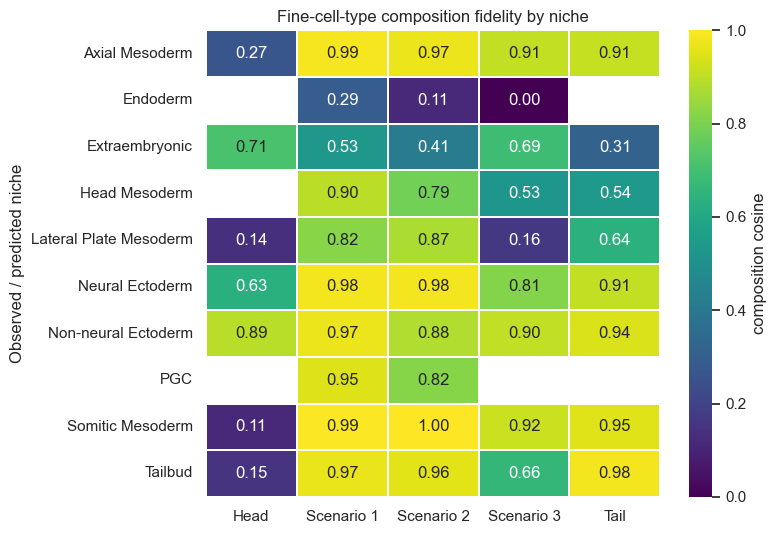

In [10]:
cosine_panel = per_niche.pivot(index="niche", columns="scenario_label", values="cosine")
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(cosine_panel, cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f", linewidths=0.3, linecolor="white", cbar_kws={"label": "composition cosine"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Observed / predicted niche")
ax.set_title("Fine-cell-type composition fidelity by niche")
fig.tight_layout()
display(fig)
plt.close(fig)


## 6. Inspect composition and spatial niches in the middle-gap scenario

The heatmaps retain all 51 components (log1p of within-niche fractions). The
spatial panels use measured cells from held-out section 9; predicted niches
come only from training-section annotations.


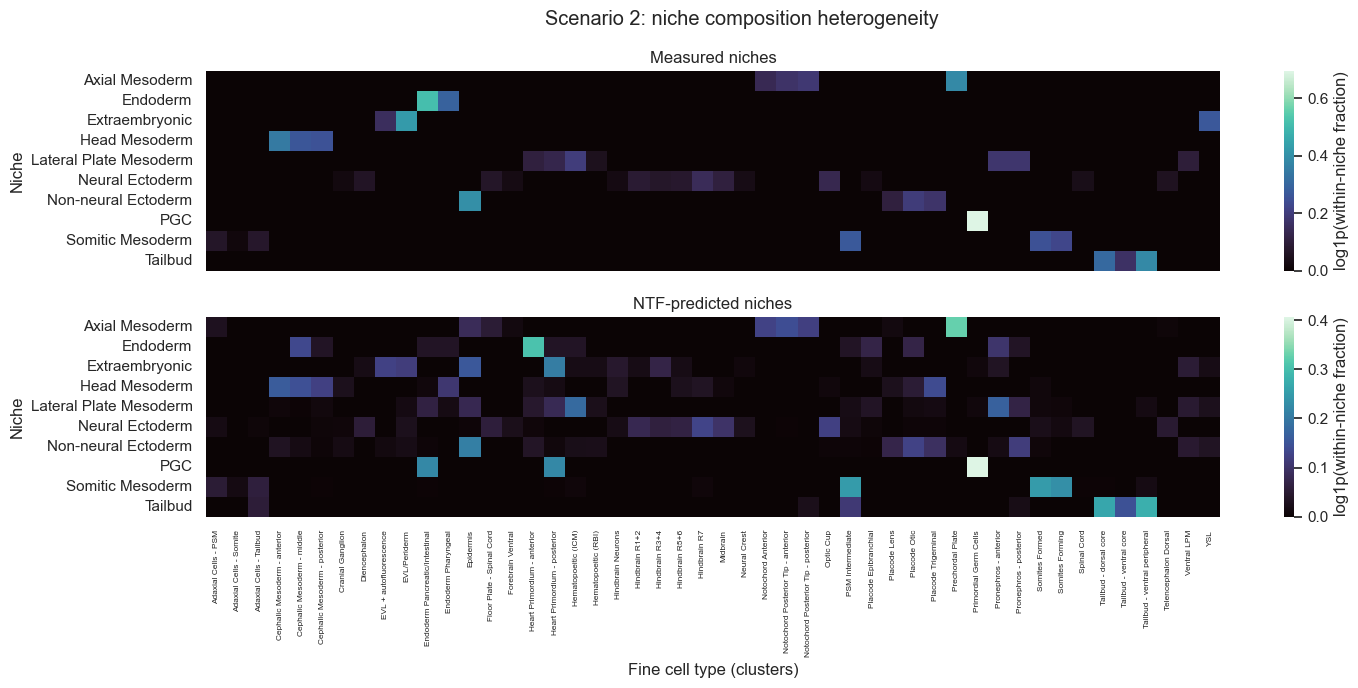

In [11]:
scenario = "senario2"
gt_comp, pred_comp = composition_store[scenario]
components = gt_comp.columns.union(pred_comp.columns)
niches = gt_comp.index.union(pred_comp.index)
gt_comp = gt_comp.reindex(index=niches, columns=components, fill_value=0.0)
pred_comp = pred_comp.reindex(index=niches, columns=components, fill_value=0.0)
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, matrix, title in zip(axes, [gt_comp, pred_comp], ["Measured niches", "NTF-predicted niches"]):
    sns.heatmap(np.log1p(matrix), cmap="mako", cbar_kws={"label": "log1p(within-niche fraction)"}, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Niche")
axes[-1].set_xlabel("Fine cell type (clusters)")
axes[-1].tick_params(axis="x", labelsize=6)
fig.suptitle("Scenario 2: niche composition heterogeneity")
fig.tight_layout()
display(fig)
plt.close(fig)


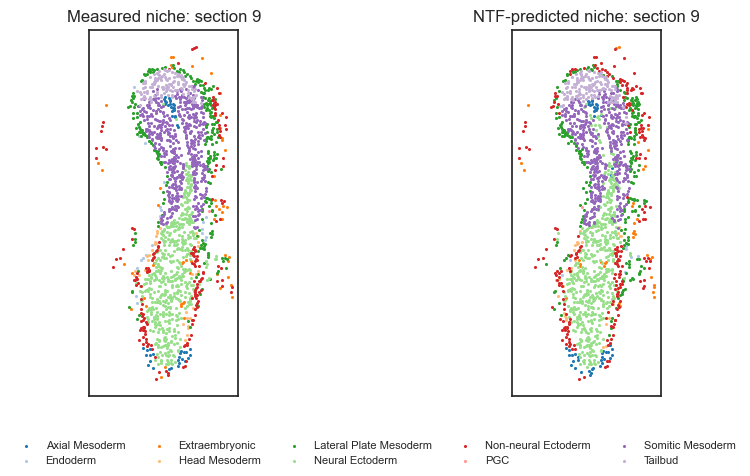

Tutorial 2 finished successfully.


In [12]:
result = results[scenario]
section_id = 9
mask = result.obs["slice_id"].astype(int).eq(section_id).to_numpy()
coords = result.obsm["spatial"]
categories = sorted(result.obs["type"].astype(str).unique())
palette = dict(zip(categories, sns.color_palette("tab20", len(categories))))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, key, title in zip(axes, ["type", "pred_type"], ["Measured niche", "NTF-predicted niche"]):
    labels = result.obs[key].astype(str).to_numpy()
    for category in categories:
        selected = mask & (labels == category)
        ax.scatter(coords[selected, 0], coords[selected, 1], s=5, color=palette[category], label=category, linewidths=0)
    ax.set_title(f"{title}: section {section_id}")
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=8)
fig.tight_layout(rect=[0, 0.12, 1, 1])
display(fig)
plt.close(fig)

print("Tutorial 2 finished successfully.")
